# Inflação, salário mínimo, juros e dólar: 2015 a 2026

Perguntas simples, respondidas com dados abertos do **Banco Central** (API SGS, sem cadastro):

1. Quanto os preços subiram desde 2015, e em quais anos a inflação passou do limite da meta?
2. O salário mínimo ganhou ou perdeu da inflação?
3. O que subiu mais: comida, moradia, transporte, educação...?
4. Com a Selic em 13,75%, quanto é o juro **de verdade**, descontada a inflação?
5. O dólar subiu mais ou menos que os preços aqui dentro?

Os dados são baixados por `python -m inflacao.coleta` e ficam em `dados/`. As contas estão em
`inflacao/calculos.py`, cada uma com teste.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from inflacao.calculos import acumulada, em_12_meses, ganho_real, indice, por_ano, valor_corrigido
from inflacao.coleta import carregar

plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10.5, "axes.titleweight": "bold", "axes.titlesize": 12,
})
AZUL, LARANJA, CINZA, VERMELHO, VERDE = "#2563eb", "#ea580c", "#6b7280", "#dc2626", "#16a34a"
reais = lambda v: f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
pct = lambda v: f"{v:.1f}%".replace(".", ",")

def salvar(fig, nome):
    fig.savefig(f"docs/{nome}.png", bbox_inches="tight", dpi=130)

ipca = carregar("ipca")
print(f"IPCA de {ipca.index.min():%m/%Y} a {ipca.index.max():%m/%Y}: {len(ipca)} meses")

IPCA de 01/2015 a 10/2026: 142 meses


## 1. Quanto os preços subiram

O IPCA sai como variação de cada mês. Pra saber o acumulado não dá pra somar os meses: as
variações se multiplicam (1% e depois 2% dá 3,02%, não 3%). Detalhes em `calculos.py`.

In [2]:
total = acumulada(ipca)
print(f"Inflação acumulada: {pct(total)}")
print(f"O que custava R$ 100,00 em jan/2015 custa {reais(valor_corrigido(100, ipca))} em {ipca.index.max():%m/%Y}")

Inflação acumulada: 89,8%
O que custava R$ 100,00 em jan/2015 custa R$ 189,82 em 10/2026


Cada ano tem uma **meta de inflação** definida pelo Conselho Monetário Nacional, com uma margem
de tolerância. Abaixo, a inflação de cada ano fechado contra o intervalo aceito.

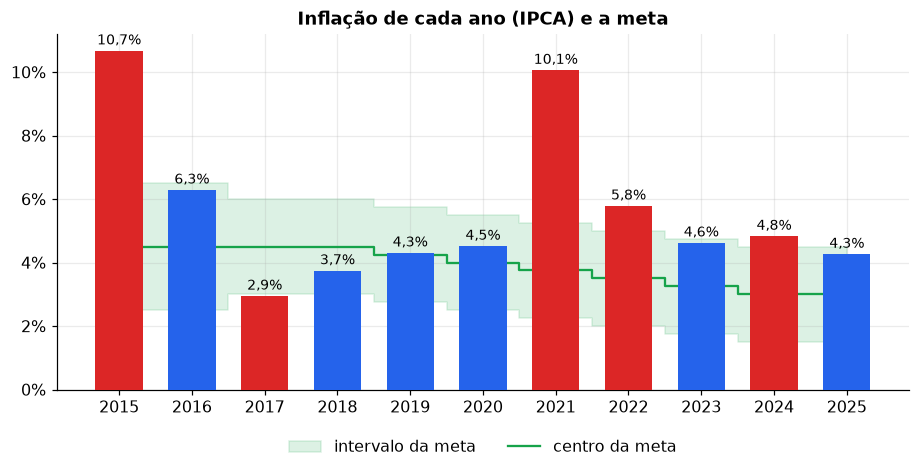

,ipca,meta,piso,teto,situacao
2015,10.67,4.50,2.50,6.50,acima do teto
2016,6.29,4.50,2.50,6.50,dentro
2017,2.95,4.50,3.00,6.00,abaixo do piso
2018,3.75,4.50,3.00,6.00,dentro
2019,4.31,4.25,2.75,5.75,dentro
2020,4.52,4.00,2.50,5.50,dentro
2021,10.06,3.75,2.25,5.25,acima do teto
2022,5.78,3.50,2.00,5.00,acima do teto
2023,4.62,3.25,1.75,4.75,dentro
2024,4.83,3.00,1.50,4.50,acima do teto


In [3]:
# meta e tolerância (pontos percentuais) definidas pelo CMN pra cada ano
meta = pd.DataFrame({
    "meta":       [4.5, 4.5, 4.5, 4.5, 4.25, 4.0, 3.75, 3.5, 3.25, 3.0, 3.0],
    "tolerancia": [2.0, 2.0, 1.5, 1.5, 1.5,  1.5, 1.5,  1.5, 1.5,  1.5, 1.5],
}, index=range(2015, 2026))
anual = por_ano(ipca)
tabela = meta.join(anual.rename("ipca"), how="inner")
tabela["teto"] = tabela.meta + tabela.tolerancia
tabela["piso"] = tabela.meta - tabela.tolerancia
tabela["situacao"] = ["acima do teto" if r.ipca > r.teto else "abaixo do piso" if r.ipca < r.piso else "dentro"
                      for r in tabela.itertuples()]

fig, ax = plt.subplots()
cores = [VERMELHO if s != "dentro" else AZUL for s in tabela.situacao]
ax.bar(tabela.index, tabela.ipca, color=cores, width=0.65, zorder=3)
ax.fill_between(tabela.index, tabela.piso, tabela.teto, step="mid", color=VERDE, alpha=0.15, label="intervalo da meta")
ax.step(tabela.index, tabela.meta, where="mid", color=VERDE, lw=1.5, label="centro da meta")
for ano, v in tabela.ipca.items():
    ax.annotate(pct(v), (ano, v), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
ax.set_title("Inflação de cada ano (IPCA) e a meta")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xticks(tabela.index)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, ncol=2)
salvar(fig, "inflacao_anual")
plt.show()
tabela[["ipca", "meta", "piso", "teto", "situacao"]].round(2)

**O que dá pra ver:** a inflação passou do teto em **2015, 2021, 2022 e 2024**, e ficou abaixo do
piso em **2017** (quando a meta também conta como descumprida). Os dois picos, 2015 e 2021, têm
explicações conhecidas: em 2015 o reajuste de preços que o governo segurava (energia, combustível);
em 2021 o efeito da pandemia, com alta de combustível, energia e comida.

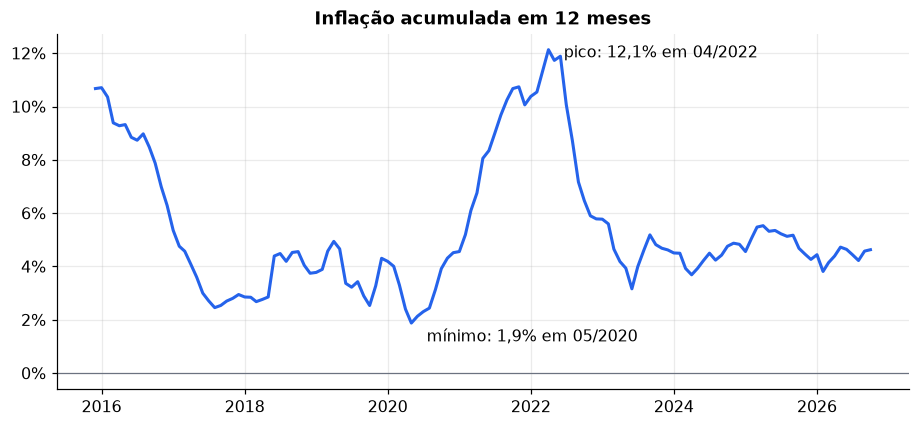

In [4]:
doze = em_12_meses(ipca).dropna()
fig, ax = plt.subplots()
ax.plot(doze.index, doze, color=AZUL, lw=2)
ax.axhline(0, color=CINZA, lw=0.8)
pico, vale = doze.idxmax(), doze.idxmin()
ax.annotate(f"pico: {pct(doze[pico])} em {pico:%m/%Y}", (pico, doze[pico]), xytext=(10, -5), textcoords="offset points")
ax.annotate(f"mínimo: {pct(doze[vale])} em {vale:%m/%Y}", (vale, doze[vale]), xytext=(10, -12), textcoords="offset points")
ax.set_title("Inflação acumulada em 12 meses")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
salvar(fig, "inflacao_12_meses")
plt.show()

## 2. O salário mínimo ganhou da inflação?

O salário mínimo de janeiro de 2015 era R$ 788. Pra comparar com o de hoje, corrijo esse valor
pela inflação acumulada desde então: se o salário de hoje for maior que o de 2015 corrigido, o
poder de compra aumentou.

Salário: R$ 788,00 em jan/2015 -> R$ 1.621,00 em 10/2026
Aumento no papel: 105,7%  |  descontada a inflação: 9,7%


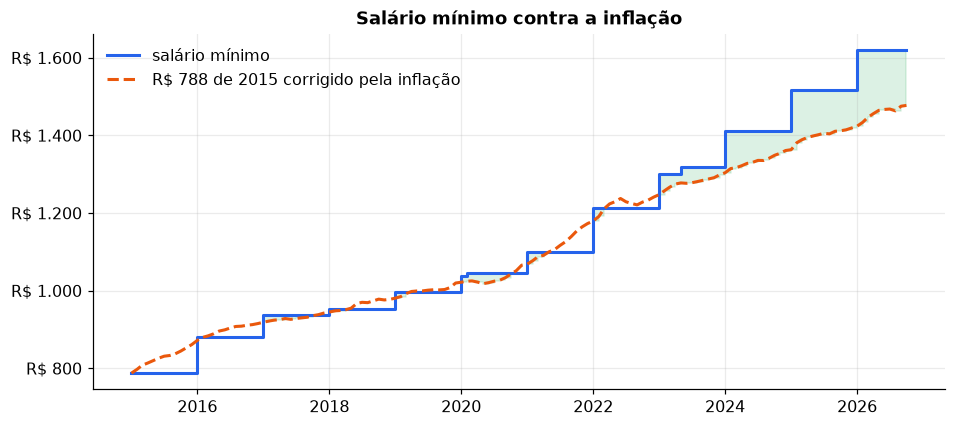

In [5]:
salario = carregar("salario_minimo")
# o IPCA de cada mês mede quanto os preços mudaram naquele mês; o salário de jan/2015 já vale
# com os preços de janeiro, então a correção começa em fevereiro
fim = ipca.index.max()
indice_precos = indice(ipca.loc["2015-02":]) / 100  # 1,0 = preços de jan/2015
salario_no_periodo = salario.loc[:fim]
salario_2015_corrigido = salario.iloc[0] * indice_precos.reindex(salario_no_periodo.index).fillna(1.0)

nominal = (salario_no_periodo.iloc[-1] / salario.iloc[0] - 1) * 100
real = ganho_real(nominal, acumulada(ipca.loc["2015-02":]))
print(f"Salário: {reais(salario.iloc[0])} em jan/2015 -> {reais(salario_no_periodo.iloc[-1])} em {fim:%m/%Y}")
print(f"Aumento no papel: {pct(nominal)}  |  descontada a inflação: {pct(real)}")

fig, ax = plt.subplots()
ax.step(salario_no_periodo.index, salario_no_periodo, where="post", color=AZUL, lw=2, label="salário mínimo")
ax.plot(salario_2015_corrigido.index, salario_2015_corrigido, color=LARANJA, lw=2, ls="--",
        label="R$ 788 de 2015 corrigido pela inflação")
ax.fill_between(salario_no_periodo.index, salario_2015_corrigido, salario_no_periodo, step="post",
                where=salario_no_periodo >= salario_2015_corrigido, color=VERDE, alpha=0.15)
ax.set_title("Salário mínimo contra a inflação")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"R$ {v:,.0f}".replace(",", ".")))
ax.legend(frameon=False)
salvar(fig, "salario_minimo")
plt.show()

**O que dá pra ver:** o salário mínimo dobrou no papel (de R$ 788 para R$ 1.621, +106%), mas a
maior parte disso só repôs a inflação. O ganho de poder de compra no período todo foi de
aproximadamente **10%**. O gráfico mostra o detalhe: dentro de cada ano a linha da inflação sobe
e encosta no salário, e o reajuste de janeiro abre a distância de novo. Em 2021 e 2022, anos de
inflação alta, o salário passou boa parte do ano abaixo da linha. O ganho real se concentra a
partir de 2023, quando os reajustes voltaram a ficar acima da inflação.

## 3. O que subiu mais

O IPCA é uma média de nove grupos de despesa. Cada grupo tem sua própria série no Banco Central.

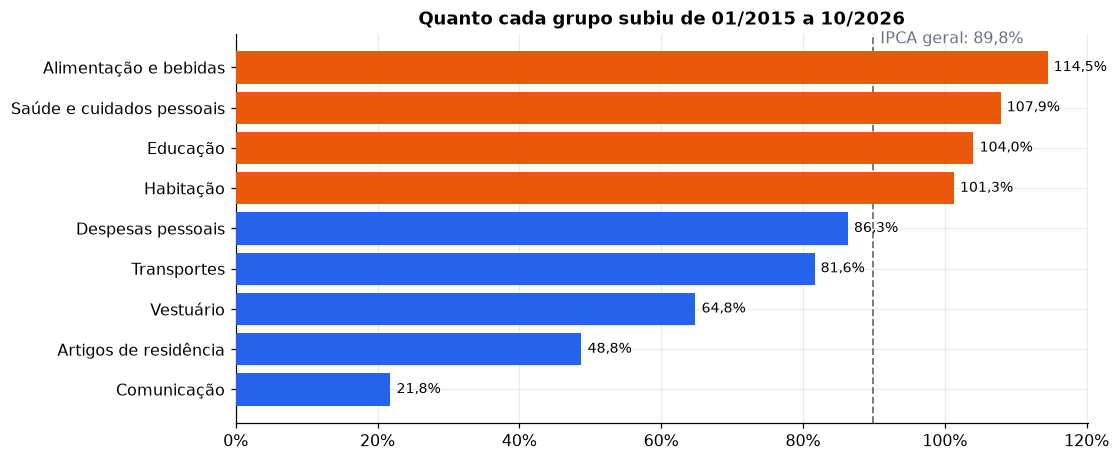

In [6]:
nomes = {
    "alimentacao": "Alimentação e bebidas", "habitacao": "Habitação", "artigos_residencia": "Artigos de residência",
    "vestuario": "Vestuário", "transportes": "Transportes", "comunicacao": "Comunicação",
    "saude": "Saúde e cuidados pessoais", "despesas_pessoais": "Despesas pessoais", "educacao": "Educação",
}
grupos = pd.Series({nome: acumulada(carregar(f"ipca_{chave}")) for chave, nome in nomes.items()}).sort_values()

fig, ax = plt.subplots(figsize=(10, 4.6))
cores = [LARANJA if v > total else AZUL for v in grupos]
ax.barh(grupos.index, grupos, color=cores, zorder=3)
ax.axvline(total, color=CINZA, ls="--", lw=1.2)
ax.annotate(f"IPCA geral: {pct(total)}", (total, len(grupos) - 0.4), xytext=(5, 0), textcoords="offset points", color=CINZA)
for i, v in enumerate(grupos):
    ax.annotate(pct(v), (v, i), va="center", xytext=(4, 0), textcoords="offset points", fontsize=9)
ax.set_title(f"Quanto cada grupo subiu de {ipca.index.min():%m/%Y} a {ipca.index.max():%m/%Y}")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
salvar(fig, "grupos")
plt.show()

**O que dá pra ver:** **comida, saúde, educação e moradia** subiram mais que a média, todas
acima de 100% (ou seja, os preços mais que dobraram). Vestuário, artigos de casa e comunicação
subiram bem menos. Isso explica por que a inflação "sentida" costuma ser maior que a oficial
para quem ganha menos: comida e moradia pesam mais no orçamento dessas famílias do que no IPCA,
que é uma média.

## 4. Juro de verdade

A Selic é o juro básico da economia, definido pelo Copom. O que importa pra quem investe (ou
pega empréstimo) é o juro **real**: quanto o dinheiro rende acima da inflação.

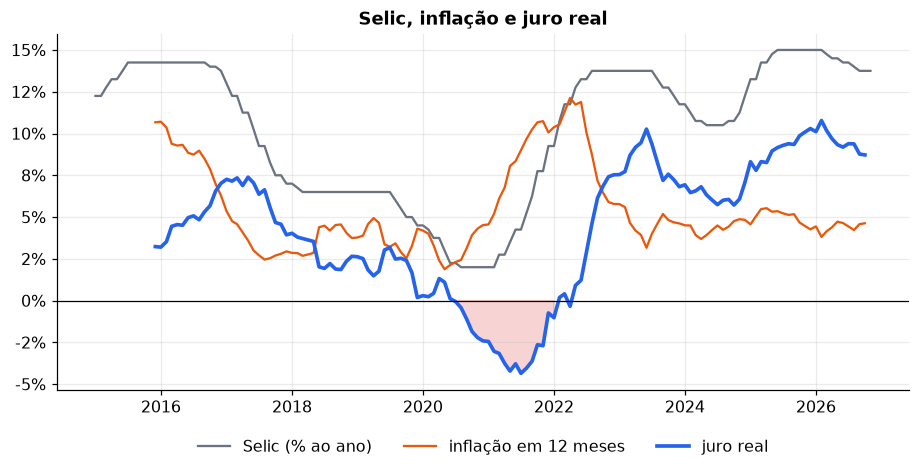

Juro real mais baixo: -4,4% em 07/2021
Juro real mais alto:  10,8% em 02/2026
Agora: Selic 13,8%, inflação 4,6%, juro real 8,7%


In [7]:
selic = carregar("selic").resample("MS").last()
juro_real = ((1 + selic / 100) / (1 + doze / 100) - 1) * 100

fig, ax = plt.subplots()
ax.plot(selic.index, selic, color=CINZA, lw=1.5, label="Selic (% ao ano)")
ax.plot(doze.index, doze, color=LARANJA, lw=1.5, label="inflação em 12 meses")
ax.plot(juro_real.index, juro_real, color=AZUL, lw=2.4, label="juro real")
ax.axhline(0, color="black", lw=0.8)
ax.fill_between(juro_real.index, juro_real, 0, where=juro_real < 0, color=VERMELHO, alpha=0.2)
ax.set_title("Selic, inflação e juro real")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
salvar(fig, "juro_real")
plt.show()
r = juro_real.dropna()
print(f"Juro real mais baixo: {pct(r.min())} em {r.idxmin():%m/%Y}")
print(f"Juro real mais alto:  {pct(r.max())} em {r.idxmax():%m/%Y}")
print(f"Agora: Selic {pct(selic.iloc[-1])}, inflação {pct(doze.iloc[-1])}, juro real {pct(r.iloc[-1])}")

**O que dá pra ver:** de meados de 2020 ao começo de 2022 a Selic ficou em 2% com a inflação subindo, e o juro
real ficou **negativo** (área vermelha): quem deixava dinheiro em renda fixa atrelada à Selic
perdia poder de compra. Depois o Banco Central subiu os juros com força pra segurar a inflação, e
o juro real foi pra perto de **10% ao ano** em 2023 e de novo em 2025 e 2026.

## 5. Dólar contra a inflação

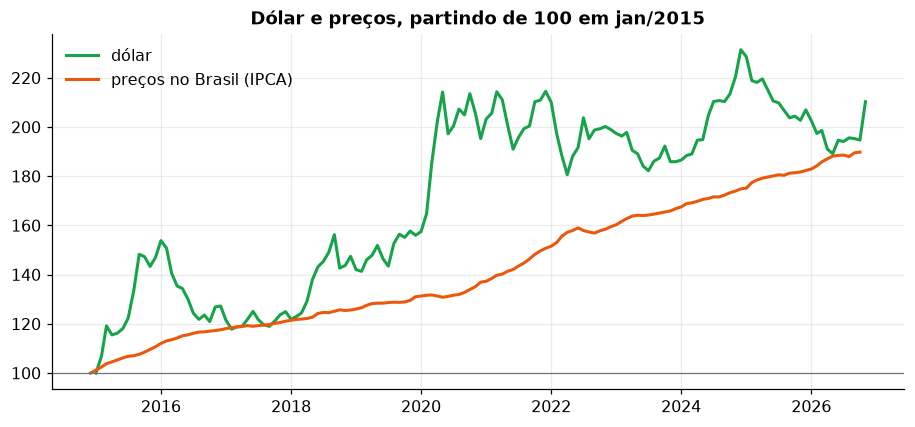

Dólar: R$ 2,69 -> R$ 5,65 (109,9%)
Preços no Brasil no mesmo período: 89,8%


In [8]:
dolar = carregar("dolar")
mensal = dolar.resample("MS").mean()
dolar_idx = mensal / mensal.iloc[0] * 100
precos_idx = pd.concat([pd.Series([100.0], index=[ipca.index[0] - pd.offsets.MonthBegin()]), indice(ipca)])

fig, ax = plt.subplots()
ax.plot(dolar_idx.index, dolar_idx, color=VERDE, lw=2, label="dólar")
ax.plot(precos_idx.index, precos_idx, color=LARANJA, lw=2, label="preços no Brasil (IPCA)")
ax.axhline(100, color=CINZA, lw=0.8)
ax.set_title("Dólar e preços, partindo de 100 em jan/2015")
ax.legend(frameon=False)
salvar(fig, "dolar")
plt.show()
print(f"Dólar: R$ {dolar.iloc[0]:.2f} -> R$ {dolar.iloc[-1]:.2f} ({pct((dolar.iloc[-1] / dolar.iloc[0] - 1) * 100)})".replace(".", ","))
print(f"Preços no Brasil no mesmo período: {pct(total)}")

**O que dá pra ver:** o dólar subiu mais que os preços aqui (de R$ 2,69 para R$ 5,65, +110%,
contra +90% de inflação), com muita oscilação no caminho: o salto de 2020 aparece bem no gráfico.
Como muita coisa que se compra no Brasil tem peça ou insumo importado, o dólar alto ajuda a
explicar parte da inflação, principalmente em eletrônicos e combustível.

## Limites desta análise

- O IPCA mede famílias com renda de 1 a 40 salários mínimos em 16 capitais. Não é a inflação
  de uma família específica nem de uma cidade do interior.
- O juro real usa a inflação **passada** (12 meses). O juro real que o mercado olha usa a
  inflação **esperada**, que não está nas séries usadas aqui.
- Salário mínimo não é renda média: muita gente ganha mais, e a renda média tem outra série.